# 悬停抓取：10 秒 EKF 位置跟踪误差

直接比较 `/ekf/ekf_odom.pose.pose.position` 与 `/flygripper/geometric_controller/data.position_reference`，不进行外参换算。
默认窗口为 EKF 世界坐标 Z > 0.5 m 时 CH9 发出闭合请求后的完整 10 秒，门限为平均三维距离 2 cm，每个窗口分别输出结果。本 notebook 只离线读取 bag；图表、CSV 和 JSON 默认保存在 `/Users/lzf/Documents/wfzf/chat`。

$$
e_i=\left\|p_{\mathrm{EKF}}(t_i)-p_{\mathrm{ref}}(t_i)\right\|_2,\qquad
\bar e=\frac{1}{N}\sum_{t_i\in[t_0,t_0+10)}e_i.
$$

同时输出各轴 MAE/RMSE、三维 RMSE、峰值和时间加权均值。平均距离不是 RMSE，不去除偏置或抓取瞬态。

在仓库根目录运行 `uv run jupyter lab scripts/analyze_hover_grasp.ipynb`，内核使用项目 `.venv`；依赖为 `rosbags numpy matplotlib`。


In [347]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, Markdown, display

module_path = next((p for d in (Path.cwd(), *Path.cwd().parents)
                    for p in (d / "scripts/analyze_hover_grasp.py", d / "analyze_hover_grasp.py")
                    if p.is_file()), None)
if module_path is None:
    raise FileNotFoundError("请从 HIARM 仓库根目录或 scripts/ 启动 Jupyter")
sys.path.insert(0, str(module_path.parent))
import analyze_hover_grasp as hg
hg = importlib.reload(hg)
ROOT = module_path.parent.parent
print("分析模块：", module_path)


分析模块： /Users/lzf/Documents/wfzf/HIARM/scripts/analyze_hover_grasp.py


## 1. 数据与参数

在 `BAGS` 中设置 bag 路径。默认起点是 EKF 世界坐标 Z 严格大于 0.5 m 且数据新鲜时，CH9 从张开档（≥1900 μs）离开并持续闭合方向至少 0.1 s 的第一条消息，包括 1500 μs 过渡档；不是舵机物理完全闭合时刻。Z 是世界坐标高度，不自动减去起飞点高度；低于门限时的闭合不会推迟到后续越过门限的时刻。也可用 `MANUAL_STARTS` 指定以 bag 起点计的秒数。

EKF 位置使用 header time，控制参考使用 bag record time 并零阶保持。保留时间覆盖、采样间隙、固定目标、HOVER、飞控状态及 RC 检查。


In [348]:
BAGS = [ "/Users/lzf/Documents/wfzf/2026-10-27-23-33-49.bag"]
# 兼容直接粘贴字符串路径和 Path 对象。
BAGS = [Path(bag).expanduser() for bag in BAGS]
OUTPUT = hg.default_output_path(BAGS[0])

CFG = hg.Settings(
    threshold_m=0.02,
    window_s=10.0,
    rc_max_gap_s=1.0,
    min_grasp_z_m=0.5,  # EKF 世界坐标 Z 阈值 (m)
)

# 键必须为 bag 的绝对路径；值为以 bag 起点计的秒数。
# {} 自动检测所有候选；[49.619...] 手工选定现场核实的起点；[] 排除该 bag。
MANUAL_STARTS = {}
# MANUAL_STARTS = {str(BAGS[0].resolve()): [49.619]}

print("门限：", CFG.threshold_m * 100, "cm；窗口：", CFG.window_s, "s")
print("输出：", OUTPUT)


门限： 2.0 cm；窗口： 10.0 s
输出： /Users/lzf/Documents/wfzf/chat/2026-10-27-23-33-49_hover_grasp


## 2. 误差来源

EKF 已输出控制器使用的位置，直接与参考位置相减即可。这里衡量的是 EKF 位置跟踪误差。

图中实线为 EKF 位置，虚线为目标位置；误差定义为 EKF 位置减目标位置。


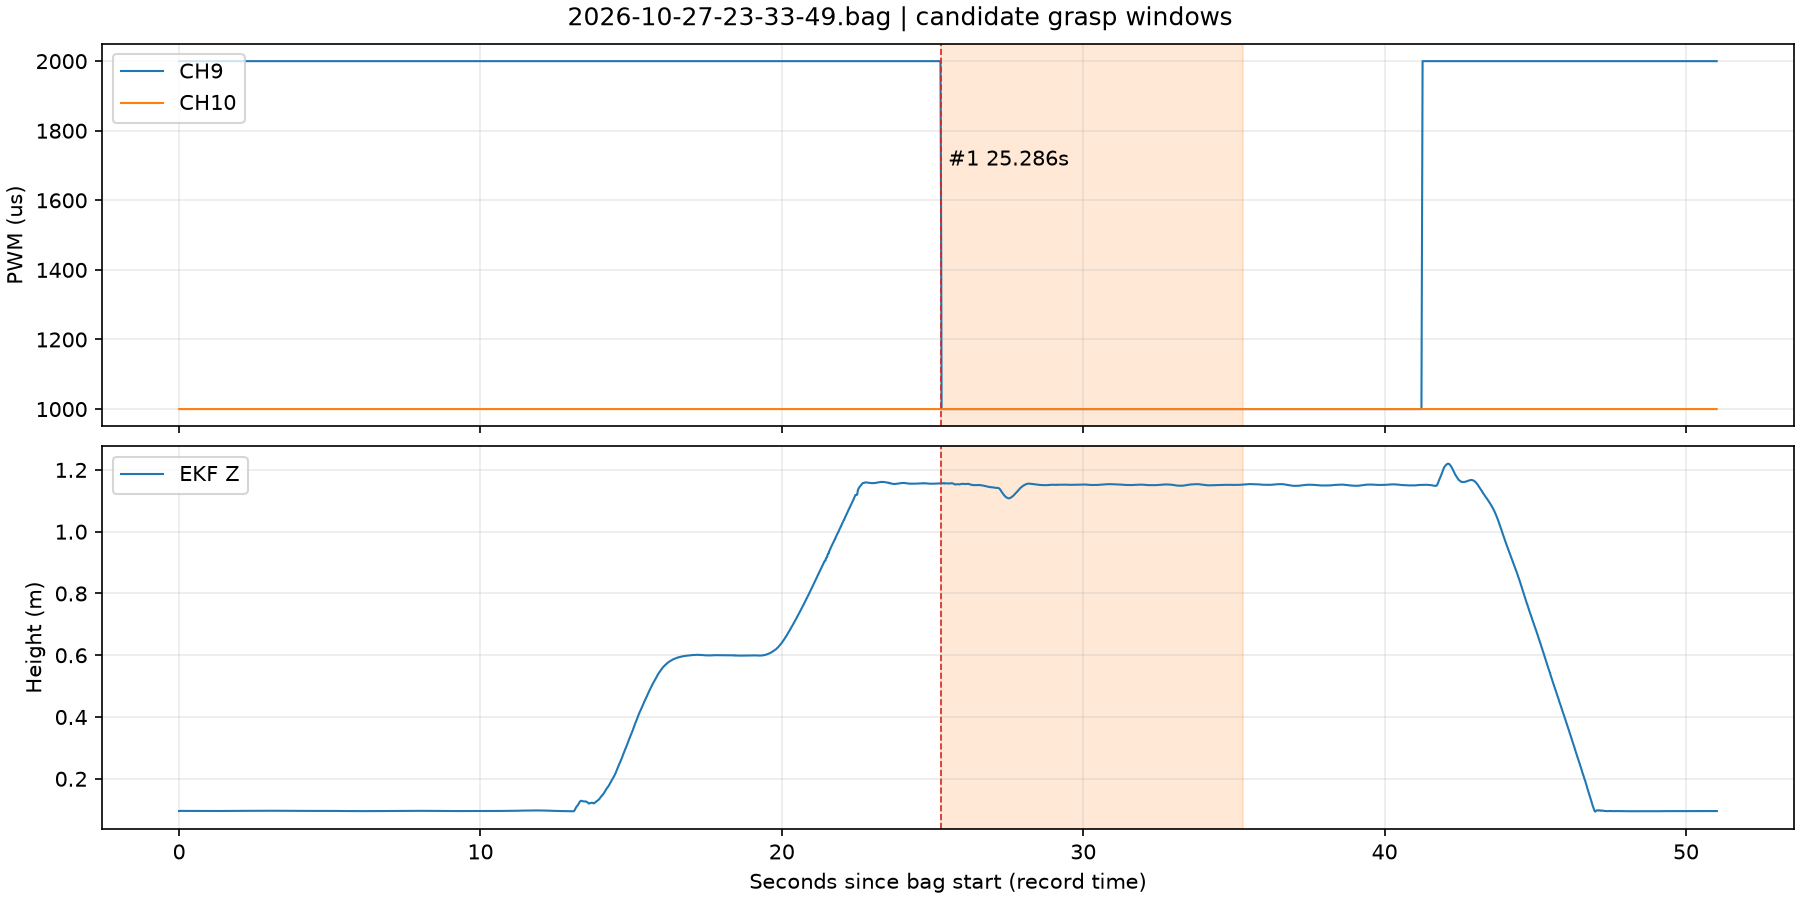

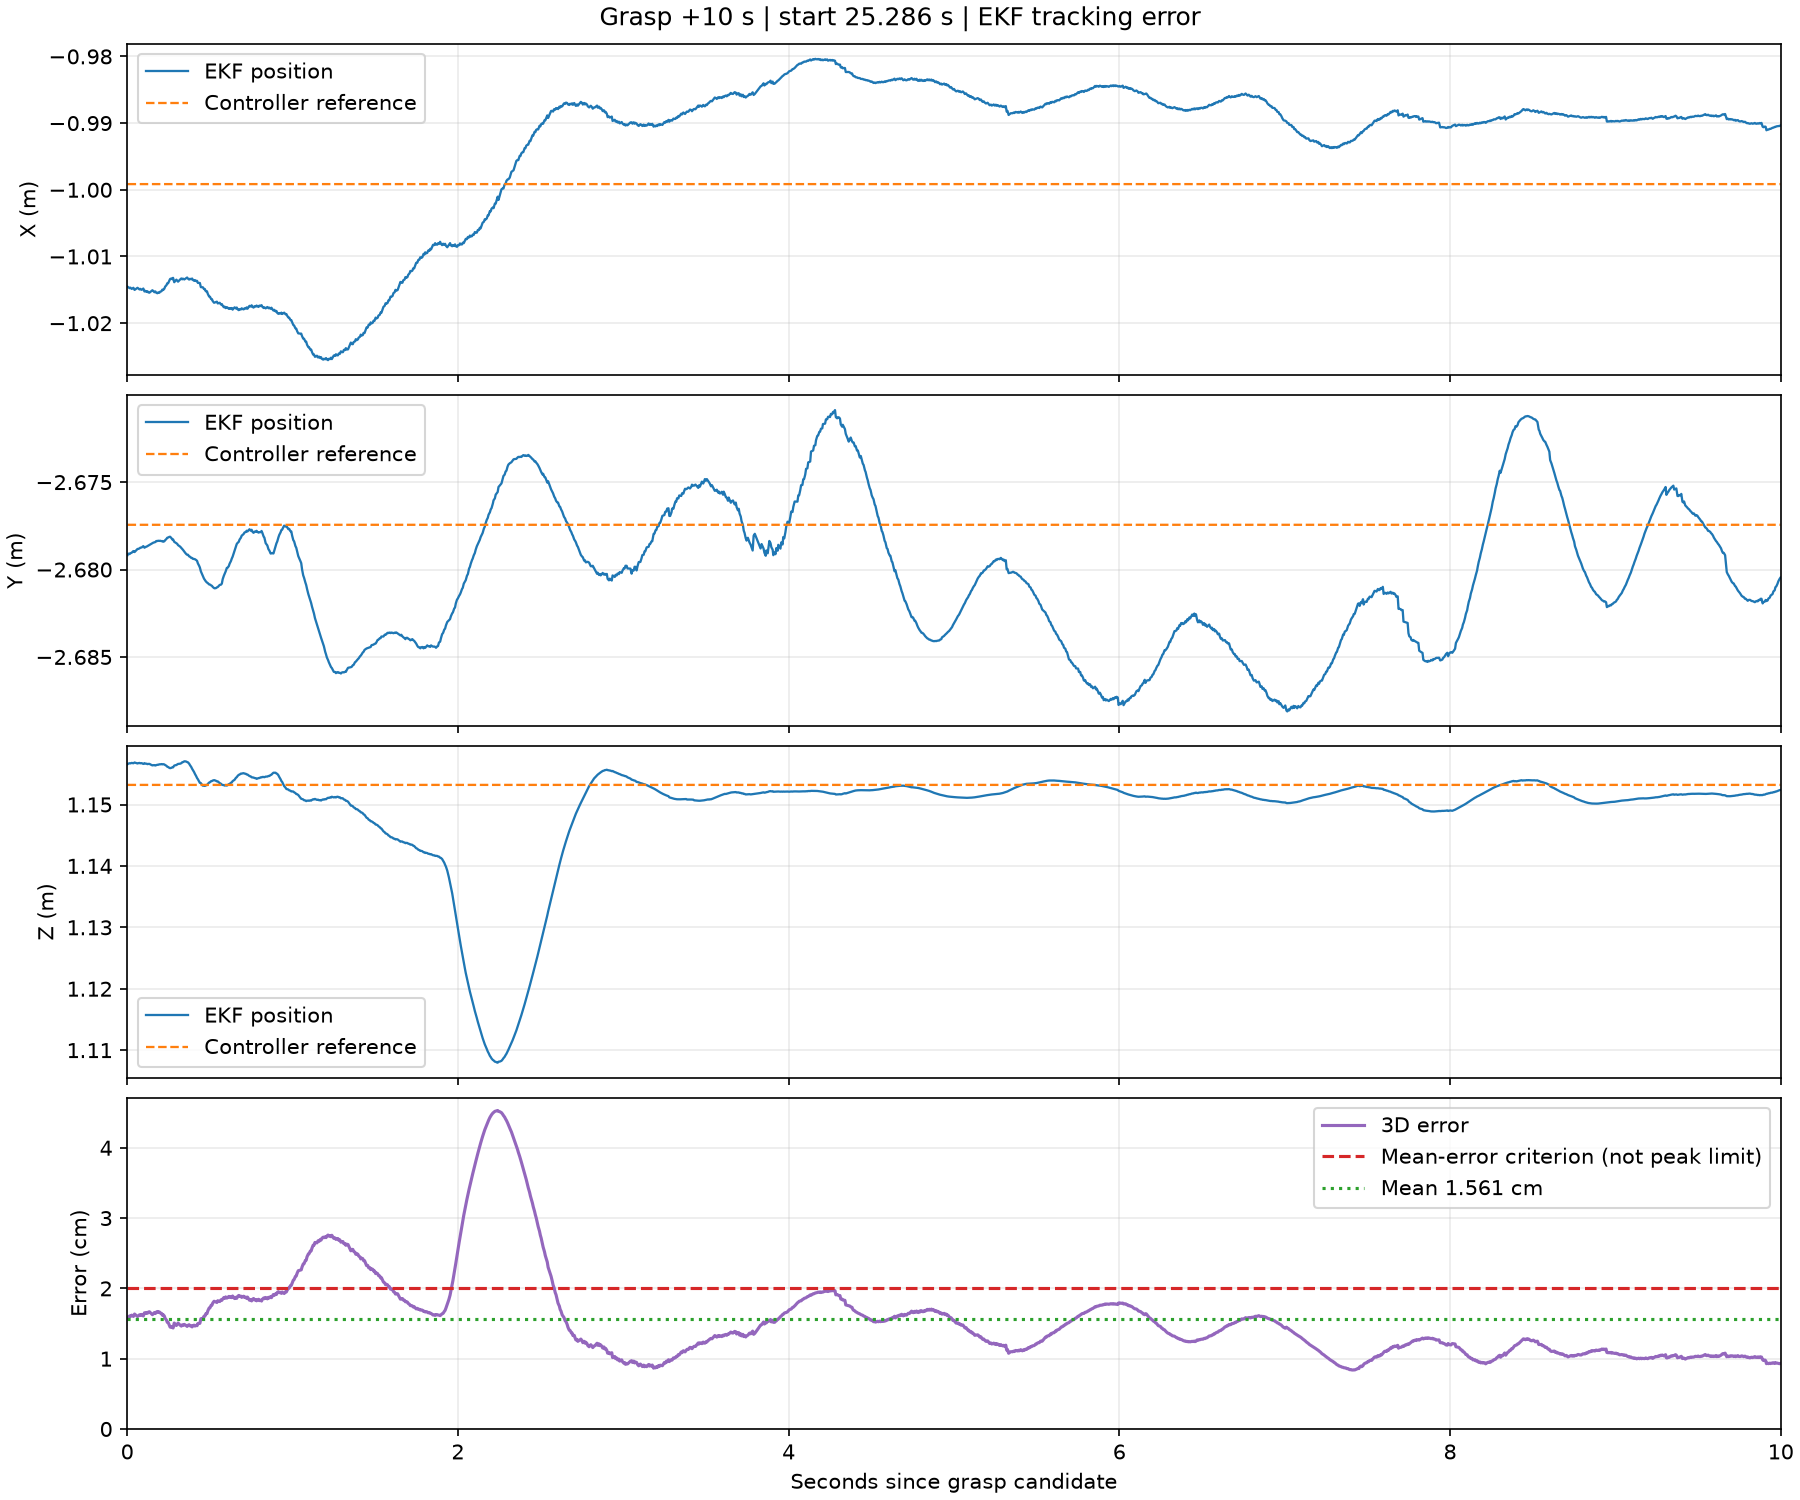

Bag： /Users/lzf/Documents/wfzf/2026-10-27-23-33-49.bag
SHA256： d78afcdda83061e3ed0ef9b384cbbf28cc9456a2bc08af9200e9e342daa306aa
时长： 51.029 s；EKF frame_id： ['world']
自动候选起点： [{'start_s': 25.286125291, 'source': 'CH9 open-to-close departure (bag record time)', 'previous_rc_s': 25.263488747, 'ekf_z_m': 1.1565244399924757, 'ekf_record_s': 25.277150998000003, 'ekf_header_s': 25.27073146, 'ch10_override': False}]
选用起点： [{'start_s': 25.286125291, 'source': 'CH9 open-to-close departure (bag record time)', 'previous_rc_s': 25.263488747, 'ekf_z_m': 1.1565244399924757, 'ekf_record_s': 25.277150998000003, 'ekf_header_s': 25.27073146, 'ch10_override': False}]


In [349]:
def show_plot(path):
    display(Image(filename=str(path)))

report = hg.analyze(BAGS, OUTPUT, CFG, manual_starts=MANUAL_STARTS, on_plot=show_plot)

for bag in report["bags"]:
    print("Bag：", bag["bag"])
    print("SHA256：", bag["sha256"])
    print("时长：", round(bag["duration_s"], 3), "s；EKF frame_id：", bag["odom_frame_ids"])
    print("自动候选起点：", bag["auto_candidates"])
    print("选用起点：", bag["selected_events"])


## 运行参数

参数快照和动态参数更新可折叠查看；展开后在固定高度区域内滚动。字段仍完整显示，并标记相对于同一话题上一条更新的变化。时间为相对 bag 起点的 record time；缺失内容标为未记录。完整数据也保存在 report.json 中。


In [350]:
import html
import json
from IPython.display import HTML, display


def show_parameter_table(title, values, previous=None):
    """折叠显示完整字段；展开后可在固定高度区域内滚动。"""
    if values is None:
        body = "<p>未记录</p>"
    else:
        items = sorted(values.items())
        if not items:
            body = "<p>无参数字段</p>"
        else:
            rows = []
            for name, value in items:
                text_value = json.dumps(value, ensure_ascii=False, sort_keys=True)
                changed = ("首次出现" if name not in previous else
                           "已变化" if previous[name] != value else "未变化") if previous is not None else "—"
                rows.append(f"<tr><td>{html.escape(name)}</td>"
                            f"<td><code>{html.escape(text_value)}</code></td><td>{changed}</td></tr>")
            table = ('<table><thead><tr><th>参数</th><th>值</th><th>与上一条比较</th>'
                     '</tr></thead><tbody>' + ''.join(rows) + '</tbody></table>')
            body = ('<div style="max-height:360px; overflow:auto; border:1px solid #ddd; '
                    'border-radius:4px;">' + table + '</div>')
        if previous is not None:
            removed = sorted(set(previous) - set(values))
            if removed:
                body += "<p>本条未包含的字段：" + html.escape(", ".join(removed)) + "</p>"
    display(HTML(
        '<details style="margin:6px 0;">'
        f'<summary style="cursor:pointer; font-weight:600;">{html.escape(title)}</summary>'
        f'<div style="padding:6px 0 0 12px;">{body}</div></details>'
    ))


for bag in report["bags"]:
    display(HTML(f"<h3>Bag：{html.escape(bag['bag'])}</h3>"))
    snapshots = bag["parameter_snapshots"]
    updates = bag["parameter_updates"]
    if not snapshots:
        display(HTML("<p>参数快照：bag 未记录或解析失败</p>"))
    for snapshot in snapshots:
        for namespace in hg.PARAMETER_NAMESPACES:
            show_parameter_table(
                f"参数快照：{snapshot['offset_s']:.3f} s；{namespace}；采集时间：{snapshot['captured_at_utc']}",
                snapshot["parameters"].get(namespace))
    if not updates:
        display(HTML("<p>动态参数更新：bag 未记录</p>"))
    previous = {}
    for update in updates:
        topic, values = update["topic"], update["parameters"]
        old = previous.get(topic)
        show_parameter_table(
            f"动态参数：{update['offset_s']:.3f} s；{topic}；" +
            ("首次记录，完整值" if old is None else "完整值及相对上一条的变化"),
            values, old)
        previous[topic] = values
    for warning in bag["parameter_warnings"]:
        display(HTML(f"<p>参数警告：{html.escape(warning)}</p>"))


参数,值,与上一条比较
actuator_state_timeout,0.1,—
admittance_max_acc_x,0.2,—
admittance_max_acc_y,0.2,—
admittance_max_acc_yaw,0.5,—
admittance_max_acc_z,0.2,—
admittance_max_vel_x,0.2,—
admittance_max_vel_y,0.2,—
admittance_max_vel_yaw,0.5,—
admittance_max_vel_z,0.2,—
admittance_mode,0,—


参数,值,与上一条比较
As_omega,-10.0,—
As_v,-3.0,—
INDI_force_bound,"{""x"": 4.0, ""y"": 4.0, ""z"": 4.0}",—
INDI_force_bound_x,4.0,—
INDI_force_bound_y,4.0,—
INDI_force_bound_z,4.0,—
INDI_torque_bound,"{""x"": 0.1, ""y"": 0.1, ""z"": 0.1}",—
INDI_torque_bound_x,0.1,—
INDI_torque_bound_y,0.1,—
INDI_torque_bound_z,0.1,—


参数,值,与上一条比较
acceleration_max,1.0,—
bodyrates_max,"{""x"": 3.14, ""y"": 3.14, ""z"": 3.14}",—
bodyrates_max_x,3.14,—
bodyrates_max_y,3.14,—
bodyrates_max_z,3.14,—
collective_thrust_max,12.0,—
collective_thrust_min,1.9204,—
dshot_rpm_map_coeff,"[-0.09288, 4.1451e-06, 1.1706e-09]",—
dshot_rpm_map_method,0,—
dshot_rpm_volt_map_coeff,"[0.0, 0.0, 0.0, 0.0]",—


参数,值,与上一条比较
admittance_max_acc_x,0.2,—
admittance_max_acc_y,0.2,—
admittance_max_acc_yaw,0.5,—
admittance_max_acc_z,0.2,—
admittance_max_vel_x,0.2,—
admittance_max_vel_y,0.2,—
admittance_max_vel_yaw,0.5,—
admittance_max_vel_z,0.2,—
admittance_mode,0,—
auto_takeoff,true,—


参数,值,与上一条比较
As_omega,-10.0,—
As_v,-3.0,—
INDI_force_bound_x,4.0,—
INDI_force_bound_y,4.0,—
INDI_force_bound_z,4.0,—
INDI_torque_bound_x,0.1,—
INDI_torque_bound_y,0.1,—
INDI_torque_bound_z,0.1,—
L1_force_bound_x,4.0,—
L1_force_bound_y,4.0,—


参数,值,与上一条比较
acceleration_max,1.0,—
bodyrates_max_x,3.14,—
bodyrates_max_y,3.14,—
bodyrates_max_z,3.14,—
collective_thrust_max,12.0,—
collective_thrust_min,1.9204,—
dshot_rpm_map_method,0,—
dynamic_mixing,false,—
hover_percentage,0.28,—
inertia_x,0.0023,—


## 3. 逐次结果

每次使用起点后的完整 10 秒，红线标示平均误差判据。目标移动、HOVER 中断、退出 GUIDED_NOGPS、非 IN_AIR、重新张开或数据覆盖不合格时，该窗口标为无效。空中状态记录仍须覆盖窗口两端，且窗口内记录均为 IN_AIR；不再限制相邻空中状态消息的间隔，稀疏记录不能证实消息之间的状态。每个窗口分别显示，跨次统计由人工处理。

修改分析规则后请重新运行 notebook；已保存的旧输出和报告不会自动更新。


In [351]:
def fmt(value, scale=1):
    return "—" if value is None else f"{value * scale:.3f}"

rows = ["| 次数 | 起点 (s) | 样本数 | 平均三维误差 (cm) | 时间均值 (cm) | RMSE (cm) | 峰值 (cm) | 数值 ≤2 cm | 窗口有效 |",
        "|---|---:|---:|---:|---:|---:|---:|---|---|"]
for r in report["trials"]:
    comparison = "未计算" if r["numeric_pass"] is None else "通过" if r["numeric_pass"] else "超标"
    rows.append(f"| {r['run']} | {r['start_s']:.3f} | {r.get('samples', '—')} | "
                f"{fmt(r.get('mean_3d_m'), 100)} | {fmt(r.get('time_mean_3d_m'), 100)} | "
                f"{fmt(r.get('rmse_3d_m'), 100)} | {fmt(r.get('max_3d_m'), 100)} | "
                f"{comparison} | {'是' if r['data_valid'] else '否'} |")
display(Markdown("\n".join(rows)))

for r in report["trials"]:
    print(f"\n第 {r['run']} 次：{r['bag']}")
    print("窗口问题：", r["issues"] or "未发现")
    if "mae_xyz_m" in r:
        print("XYZ MAE (cm)：", [round(v*100, 3) for v in r["mae_xyz_m"]])
        print("XYZ RMSE (cm)：", [round(v*100, 3) for v in r["rmse_xyz_m"]])
        print("目标变化 (m)：", r["reference_motion_m"])
        print("最大 EKF 间隙 (s)：", r["odom_max_gap_s"])
        print("最大 RC 间隙 (s)：", r["rc_max_gap_s"])
        print("header/record 时间差范围 (s)：", r["header_age_range_s"])

s = report["summary"]
print(f"窗口数：{s['trials']}；有效窗口：{s['valid_trials']}")
print("输出文件：", OUTPUT / "report.json", OUTPUT / "trials.csv", sep="\n")


| 次数 | 起点 (s) | 样本数 | 平均三维误差 (cm) | 时间均值 (cm) | RMSE (cm) | 峰值 (cm) | 数值 ≤2 cm | 窗口有效 |
|---|---:|---:|---:|---:|---:|---:|---|---|
| 1 | 25.286 | 1667 | 1.561 | 1.561 | 1.698 | 4.531 | 通过 | 是 |


第 1 次：/Users/lzf/Documents/wfzf/2026-10-27-23-33-49.bag
窗口问题： 未发现
XYZ MAE (cm)： [1.249, 0.421, 0.417]
XYZ RMSE (cm)： [1.324, 0.507, 0.934]
目标变化 (m)： 0.0
最大 EKF 间隙 (s)： 0.010000000000005116
最大 RC 间隙 (s)： 0.05364304700000133
header/record 时间差范围 (s)： [0.0012069080000003396, 0.0558063269999991]
窗口数：1；有效窗口：1
输出文件：
/Users/lzf/Documents/wfzf/chat/2026-10-27-23-33-49_hover_grasp/report.json
/Users/lzf/Documents/wfzf/chat/2026-10-27-23-33-49_hover_grasp/trials.csv
